In [5]:
import pandas as pd

path = r"C:\Users\27395\Desktop\superstore项目\data\Sample - Superstore.csv"
lines = open(path, encoding="gb18030").read().splitlines()

header = ["ID","订单ID","订购日期","发货日期","运输方式","客户ID","客户姓名","客户类别",
          "国家","城市","州","邮政编码","地区","产品ID","产品类别","产品子类别",
          "产品名称","销售额","产品数量","折扣","利润/亏损"]

records = []
for line in lines[1:]:
    parts = line.split(",")
    while parts and parts[-1].strip() == "":   # 去掉行尾多余的空列
        parts.pop()
    name = ",".join(parts[16:-4])                # 中间所有内容拼回产品名
    records.append(parts[:16] + [name] + parts[-4:])

df = pd.DataFrame(records, columns=header)

# 转类型
df["销售额"] = df["销售额"].astype(float)
df["产品数量"] = df["产品数量"].astype(int)
df["折扣"] = df["折扣"].astype(float)
df["利润/亏损"] = df["利润/亏损"].astype(float)
df["订购日期"] = pd.to_datetime(df["订购日期"], format="%m/%d/%Y")
df["发货日期"] = pd.to_datetime(df["发货日期"], format="%m/%d/%Y")

print(df.shape)
print(df.dtypes)

(9994, 21)
ID                  str
订单ID                str
订购日期     datetime64[us]
发货日期     datetime64[us]
运输方式                str
客户ID                str
客户姓名                str
客户类别                str
国家                  str
城市                  str
州                   str
邮政编码                str
地区                  str
产品ID                str
产品类别                str
产品子类别               str
产品名称                str
销售额             float64
产品数量              int64
折扣              float64
利润/亏损           float64
dtype: object


In [6]:
df = df.drop(columns=["ID"])

In [9]:
print("重复行数:", df.duplicated().sum())

df = df.drop_duplicates()
print("删除后形状:", df.shape)

重复行数: 1
删除后形状: (9993, 20)


In [10]:
total_sales   = df["销售额"].sum()
total_profit  = df["利润/亏损"].sum()
profit_margin = total_profit / total_sales

print(f"总销售额: {total_sales:,.2f}")
print(f"总利润:   {total_profit:,.2f}")
print(f"利润率:   {profit_margin:.2%}")
print(f"订单数:   {df['订单ID'].nunique()}")
print(f"客户数:   {df['客户ID'].nunique()}")

总销售额: 2,296,919.49
总利润:   286,409.08
利润率:   12.47%
订单数:   5009
客户数:   793


In [15]:
cat = df.groupby("产品类别")[["销售额", "利润/亏损"]].sum()
cat["利润率"] = cat["利润/亏损"] / cat["销售额"]
cat.sort_values("销售额", ascending=False)

,销售额,利润/亏损,利润率
产品类别,,,
Technology,836154.0330,145454.9481,0.173957
Furniture,741718.4233,18463.3316,0.024893
Office Supplies,719047.0320,122490.8008,0.170352


In [16]:
sub = df.groupby(["产品类别", "产品子类别"]).agg(
    销售额=("销售额", "sum"),
    利润=("利润/亏损", "sum")
).reset_index()

sub["利润率"] = sub["利润"] / sub["销售额"]
sub.sort_values("利润")   # 利润最低的排最前面

,产品类别,产品子类别,销售额,利润,利润率
3,Furniture,Tables,206965.5320,-17725.4811,-0.085645
0,Furniture,Bookcases,114879.9963,-3472.5560,-0.030228
12,Office Supplies,Supplies,46673.5380,-1189.0995,-0.025477
8,Office Supplies,Fasteners,3024.2800,949.5182,0.313965
15,Technology,Machines,189238.6310,3384.7569,0.017886
9,Office Supplies,Labels,12486.3120,5546.2540,0.444187
5,Office Supplies,Art,27118.7920,6527.7870,0.240711
7,Office Supplies,Envelopes,16476.4020,6964.1767,0.422676
2,Furniture,Furnishings,91705.1640,13059.1436,0.142404
4,Office Supplies,Appliances,107532.1610,18138.0054,0.168675


In [17]:
tables = df[df["产品子类别"] == "Tables"]

print("桌子订单数:", tables["订单ID"].nunique())
print(tables["折扣"].describe())

桌子订单数: 307
count    319.000000
mean       0.261285
std        0.169622
min        0.000000
25%        0.200000
50%        0.300000
75%        0.400000
max        0.500000
Name: 折扣, dtype: float64


In [18]:
tables.groupby("折扣")["利润/亏损"].agg(["count", "mean", "sum"]).round(1)

,count,mean,sum
折扣,,,
0.00,72,184.4,13276.3
0.20,71,-4.3,-303.6
0.30,54,-63.0,-3402.3
0.40,75,-215.8,-16187.4
0.45,11,-226.6,-2493.1
0.50,36,-239.3,-8615.4


In [19]:
region = df.groupby("地区").agg(销售额=("销售额", "sum"), 利润=("利润/亏损", "sum"))
region["利润率"] = region["利润"] / region["销售额"]
region.sort_values("利润")

,销售额,利润,利润率
地区,,,
Central,501239.8908,39706.3625,0.079216
South,391721.9050,46749.4303,0.119343
East,678499.8680,91534.8388,0.134908
West,725457.8245,108418.4489,0.149448


In [22]:
state = df.groupby("州").agg(销售额=("销售额", "sum"), 利润=("利润/亏损", "sum"))
state["利润率"] = state["利润"] / state["销售额"]
state.sort_values("利润").head(10)

,销售额,利润,利润率
州,,,
Texas,170188.0458,-25729.3563,-0.151182
Ohio,77976.7640,-16959.3178,-0.217492
Pennsylvania,116511.9140,-15559.9603,-0.133548
Illinois,80166.1010,-12607.8870,-0.157272
North Carolina,55603.1640,-7490.9122,-0.134721
Colorado,32108.1180,-6527.8579,-0.203309
Tennessee,30661.8730,-5341.6936,-0.174213
Arizona,35282.0010,-3427.9246,-0.097158
Florida,89473.7080,-3399.3017,-0.037992


In [23]:
texas = df[df["州"] == "Texas"]

# 1) 德州哪些子类别在亏
texas.groupby("产品子类别")["利润/亏损"].agg(["sum", "count"]).sort_values("sum").head(10)

,sum,count
产品子类别,,
Binders,-14705.0738,153
Appliances,-6147.2225,47
Furnishings,-3312.6786,81
Machines,-2666.8434,13
Chairs,-2515.6490,61
Bookcases,-2391.1377,27
Tables,-2216.6766,33
Supplies,-837.2795,19
Storage,-763.7054,83


In [24]:
# 2) 德州的折扣与利润关系
texas.groupby("折扣")["利润/亏损"].agg(["count", "mean", "sum"]).round(1)

,count,mean,sum
折扣,,,
0.20,570,14.4,8225.9
0.30,94,-50.3,-4732.3
0.32,27,-88.6,-2391.1
0.40,13,-205.1,-2666.8
0.60,81,-40.9,-3312.7
0.80,200,-104.3,-20852.3


In [25]:
# 全公司超高折扣（>=0.6，即 4 折及以下）的品类分布
deep = df[df["折扣"] >= 0.6]
deep.groupby("产品子类别")["利润/亏损"].agg(["count", "sum"]).sort_values("sum")

,count,sum
产品子类别,,
Binders,613,-38510.4964
Machines,23,-19579.3191
Appliances,67,-8629.6412
Furnishings,138,-5944.6552
Bookcases,15,-3894.9394


In [26]:
# 再看这些超高折扣集中在哪些州
deep.groupby("州")["利润/亏损"].agg(["count", "sum"]).sort_values("sum").head(10)

,count,sum
州,,
Texas,281,-24164.9749
Ohio,81,-13171.6128
Illinois,157,-12318.7195
Colorado,40,-7172.6636
Pennsylvania,105,-6790.2206
Tennessee,29,-3635.9181
Arizona,41,-3446.8967
Florida,67,-2760.7304
North Carolina,36,-2007.8254


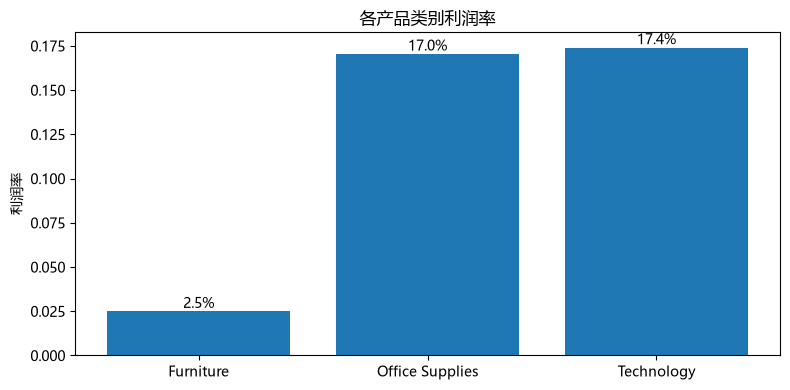

In [45]:
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

cat2 = df.groupby("产品类别").agg(销售额=("销售额", "sum"), 利润=("利润/亏损", "sum"))
cat2["利润率"] = cat2["利润"] / cat2["销售额"]

plt.figure(figsize=(8, 4))
plt.bar(cat2.index, cat2["利润率"])
plt.title("各产品类别利润率")
plt.ylabel("利润率")
for i, v in enumerate(cat2["利润率"]):
    plt.text(i, v, f"{v:.1%}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("fig1_品类利润率.png", dpi=150, bbox_inches="tight")
plt.show()

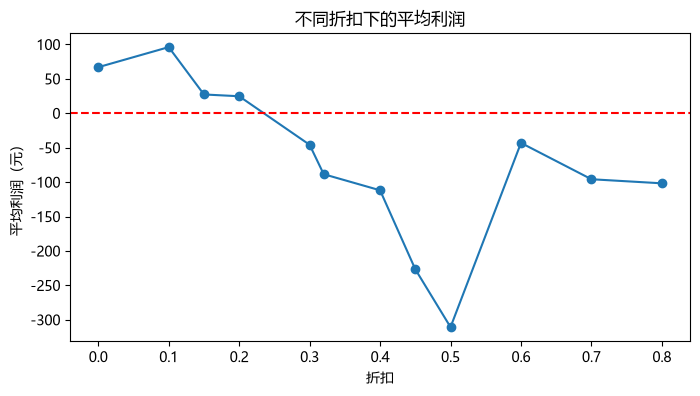

In [46]:
# 按折扣分组，算平均利润
disc = df.groupby("折扣")["利润/亏损"].agg(["count", "mean"]).reset_index()

plt.figure(figsize=(8, 4))
plt.plot(disc["折扣"], disc["mean"], marker="o")
plt.axhline(0, color="red", linestyle="--")
plt.title("不同折扣下的平均利润")
plt.xlabel("折扣")
plt.ylabel("平均利润（元）")
plt.savefig("fig2_折扣与利润.png", dpi=150, bbox_inches="tight")
plt.show()

In [42]:
df[df["折扣"] == 0.5].groupby("产品子类别")["利润/亏损"].sum().sort_values().head()

产品子类别
Tables      -8615.3873
Machines    -7635.2291
Bookcases   -4255.8117
Name: 利润/亏损, dtype: float64

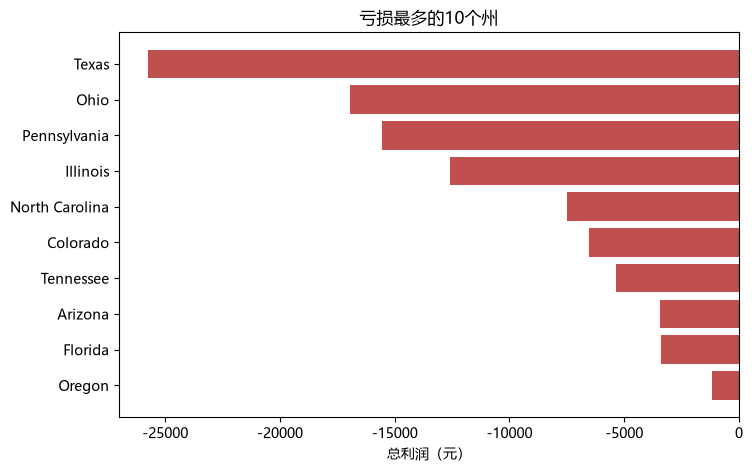

In [48]:
state2 = df.groupby("州")["利润/亏损"].sum().sort_values().head(10)

plt.figure(figsize=(8, 5))
plt.barh(state2.index, state2.values, color="#c0504d")
plt.title("亏损最多的10个州")
plt.xlabel("总利润（元）")
plt.gca().invert_yaxis()
plt.savefig("fig3_州亏损TOP10.png", dpi=150, bbox_inches="tight")
plt.show()